# Machine Learning Supervisado — Regresión Logística y Clasificación
**Universidad de Cundinamarca — Esp. Inteligencia Artificial**
**CADI – Introducción a Machine Learning — Periodo 2026-2**
Docente: Ing. Wilson Rojas Reales, PhD(c)

> Repositorio: https://github.com/Yohann0011/ml-supervisado-clasificacion-ucundinamarca
> Este notebook se ejecuta de extremo a extremo en **Google Colab** (runtime CPU).

# Notebook 03 — Puente con la práctica anterior (regresión lineal → clasificación)

Valida el OLS inmobiliario de la semana anterior (Excel `=ESTIMACION.LINEAL`) y resuelve el
mismo fenómeno como clasificación binaria (segmento premium).


In [1]:
try:
    import google.colab  # noqa
    EN_COLAB = True
    !git clone --depth 1 https://github.com/Yohann0011/ml-supervisado-clasificacion-ucundinamarca repo 2>/dev/null
    import os
    if os.path.isdir('repo'): os.chdir('repo')
except Exception:
    EN_COLAB = False

import os, sys
from pathlib import Path
RAIZ = Path(os.environ.get('RAIZ_ML', '.'))
for p in (str(RAIZ), str(RAIZ / 'src')):
    if p not in sys.path:
        sys.path.insert(0, p)

%matplotlib inline
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
from config import SEED, DIR_DATA, DIR_FIGS
print('Semilla:', SEED, '| datos en:', DIR_DATA)


OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k


OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k


Semilla: 42 | datos en: /tmp/arena/tenants/e8826d75-4142-4def-a7d6-6372192c98b1/sessions/36353820-3eae-42c9-a669-90aac76b7923/workspace/ml_informe/../ml_informe/data


In [2]:
from puente_inmobiliario import parte1_validacion_ols, parte2_clasificacion
ols = parte1_validacion_ols()
pd.DataFrame({'excel': ols['excel'], 'python': ols['python']}).T

OLS replicado: {'intercepto': 38466.875122, 'coef_area': 2466.630838, 'coef_habitaciones': 12214.188001, 'r2': 0.999749988, 'rmse': 2043.96, 'mae': 1767.76}
Diferencias vs Excel: {'intercepto': 1.42e-07, 'coef_area': 3.82e-07, 'coef_habitaciones': 2.18e-07, 'r2': 0.0}


,coef_habitaciones,coef_area,intercepto,r2,rmse,mae
excel,12214.188001,2466.630838,38466.875122,0.99975,NaN,NaN
python,12214.188001,2466.630838,38466.875122,0.99975,2043.96,1767.76


In [3]:
pd.DataFrame(ols['tabla'])

,Area_m2,Habitaciones,Precio_USD,Predicho,Error
0,50,1,175000,174012.61,987.39
1,65,2,220000,223226.26,-3226.26
2,70,2,235000,235559.41,-559.41
3,80,3,275000,272439.91,2560.09
4,95,3,310000,309439.37,560.63
5,110,3,345000,346438.83,-1438.83
6,120,4,385000,383319.33,1680.67
7,135,4,420000,420318.79,-318.79
8,150,4,460000,457318.25,2681.75
9,165,5,505000,506531.90,-1531.90


In [4]:
cls = parte2_clasificacion()
pd.DataFrame(cls['metricas']).T.round(3)

Regresión Logística: Acc=0.950 Prec=1.000 Rec=0.900 F1=0.947 CM[TN=10 FP=0 FN=1 TP=9]
Árbol de Decisión: Acc=0.950 Prec=1.000 Rec=0.900 F1=0.947 CM[TN=10 FP=0 FN=1 TP=9]


Random Forest: Acc=0.950 Prec=1.000 Rec=0.900 F1=0.947 CM[TN=10 FP=0 FN=1 TP=9]
SVM: Acc=0.900 Prec=1.000 Rec=0.800 F1=0.889 CM[TN=10 FP=0 FN=2 TP=8]
KNN: Acc=0.950 Prec=1.000 Rec=0.900 F1=0.947 CM[TN=10 FP=0 FN=1 TP=9]


Naive Bayes: Acc=0.950 Prec=1.000 Rec=0.900 F1=0.947 CM[TN=10 FP=0 FN=1 TP=9]
Logística estandarizada: {'coef_area_est': 3.1915, 'coef_hab_est': 0.5208, 'odds_area': 24.326, 'odds_hab': 1.6834, 'reporte': '              precision    recall  f1-score   support\n\n    Estándar      0.909     1.000     0.952        10\n     Premium      1.000     0.900     0.947        10\n\n    accuracy                          0.950        20\n   macro avg      0.955     0.950     0.950        20\nweighted avg      0.955     0.950     0.950        20\n'}


,accuracy,balanced_accuracy,precision,recall,f1,specificity,roc_auc,average_precision,tn,fp,fn,tp,fpr,fnr,mcc,kappa,cv_f1
Regresión Logística,0.95,0.95,1.0,0.9,0.947,1.0,1.00,1.00,10.0,0.0,1.0,9.0,0.0,0.1,0.904,0.9,0.962
Árbol de Decisión,0.95,0.95,1.0,0.9,0.947,1.0,0.95,0.95,10.0,0.0,1.0,9.0,0.0,0.1,0.904,0.9,0.937
Random Forest,0.95,0.95,1.0,0.9,0.947,1.0,1.00,1.00,10.0,0.0,1.0,9.0,0.0,0.1,0.904,0.9,0.950
SVM,0.90,0.90,1.0,0.8,0.889,1.0,1.00,1.00,10.0,0.0,2.0,8.0,0.0,0.2,0.816,0.8,0.933
KNN,0.95,0.95,1.0,0.9,0.947,1.0,1.00,1.00,10.0,0.0,1.0,9.0,0.0,0.1,0.904,0.9,0.962
Naive Bayes,0.95,0.95,1.0,0.9,0.947,1.0,1.00,1.00,10.0,0.0,1.0,9.0,0.0,0.1,0.904,0.9,0.975


In [5]:
print(cls['logistica']['reporte'])

              precision    recall  f1-score   support

    Estándar      0.909     1.000     0.952        10
     Premium      1.000     0.900     0.947        10

    accuracy                          0.950        20
   macro avg      0.955     0.950     0.950        20
weighted avg      0.955     0.950     0.950        20



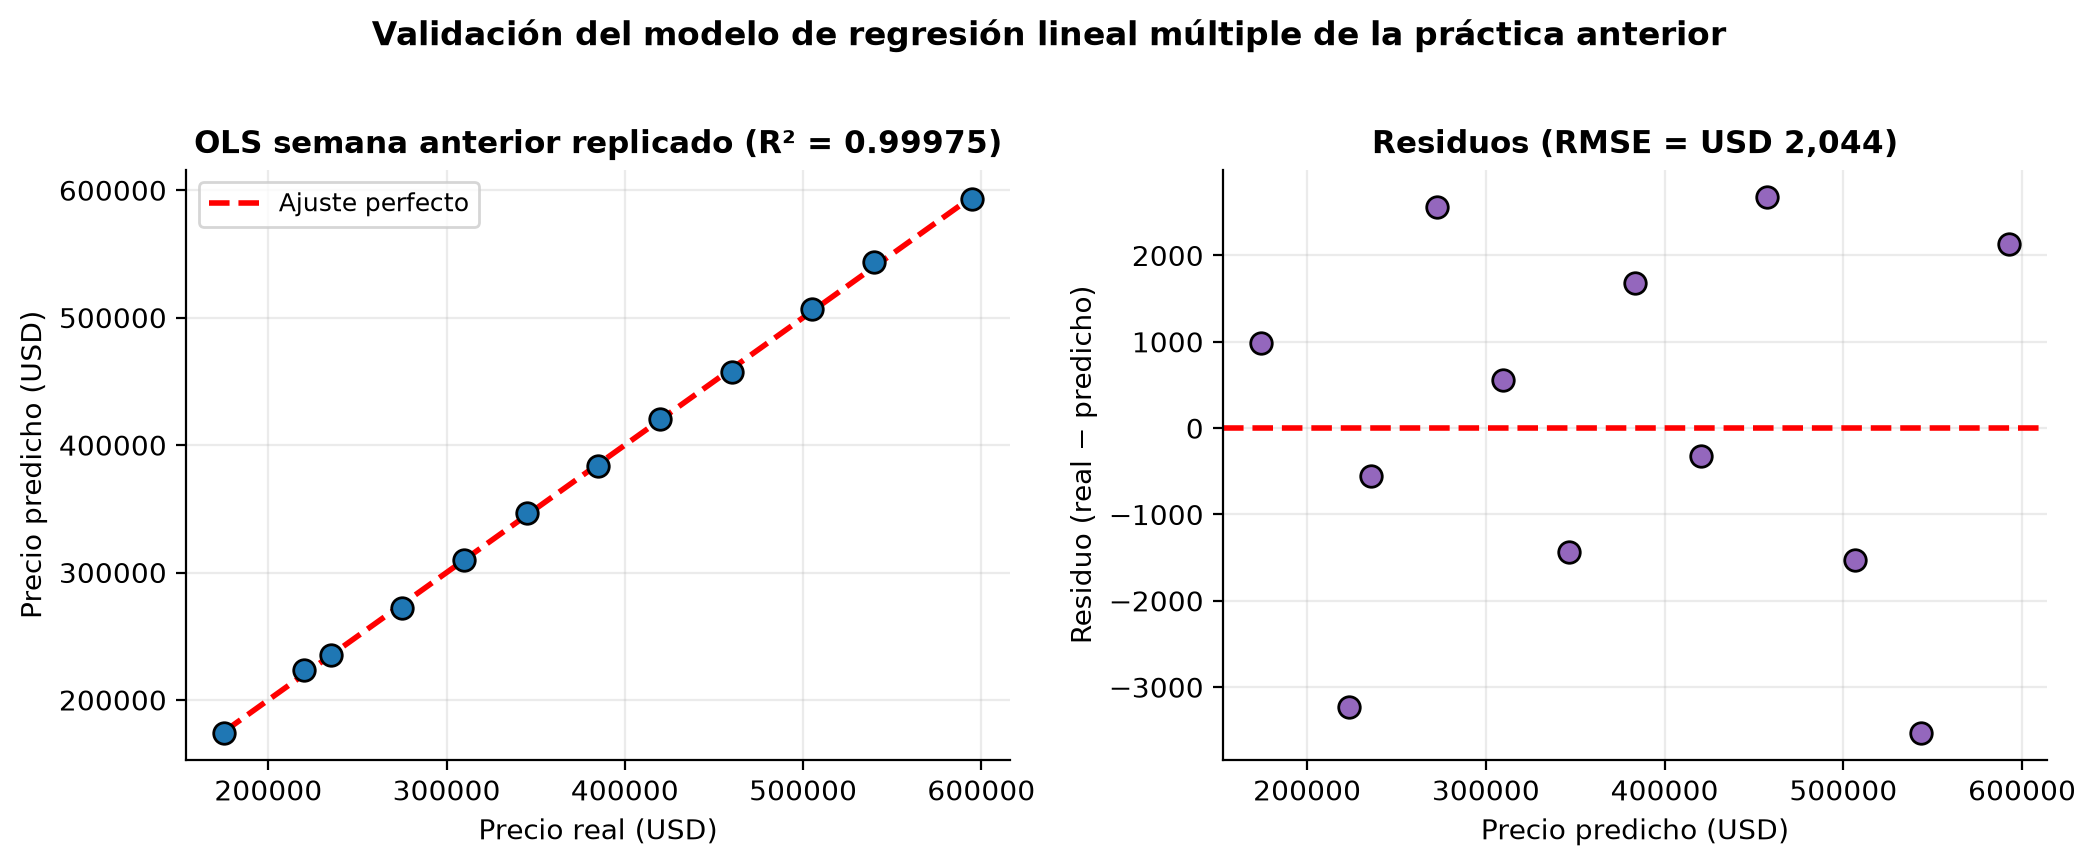

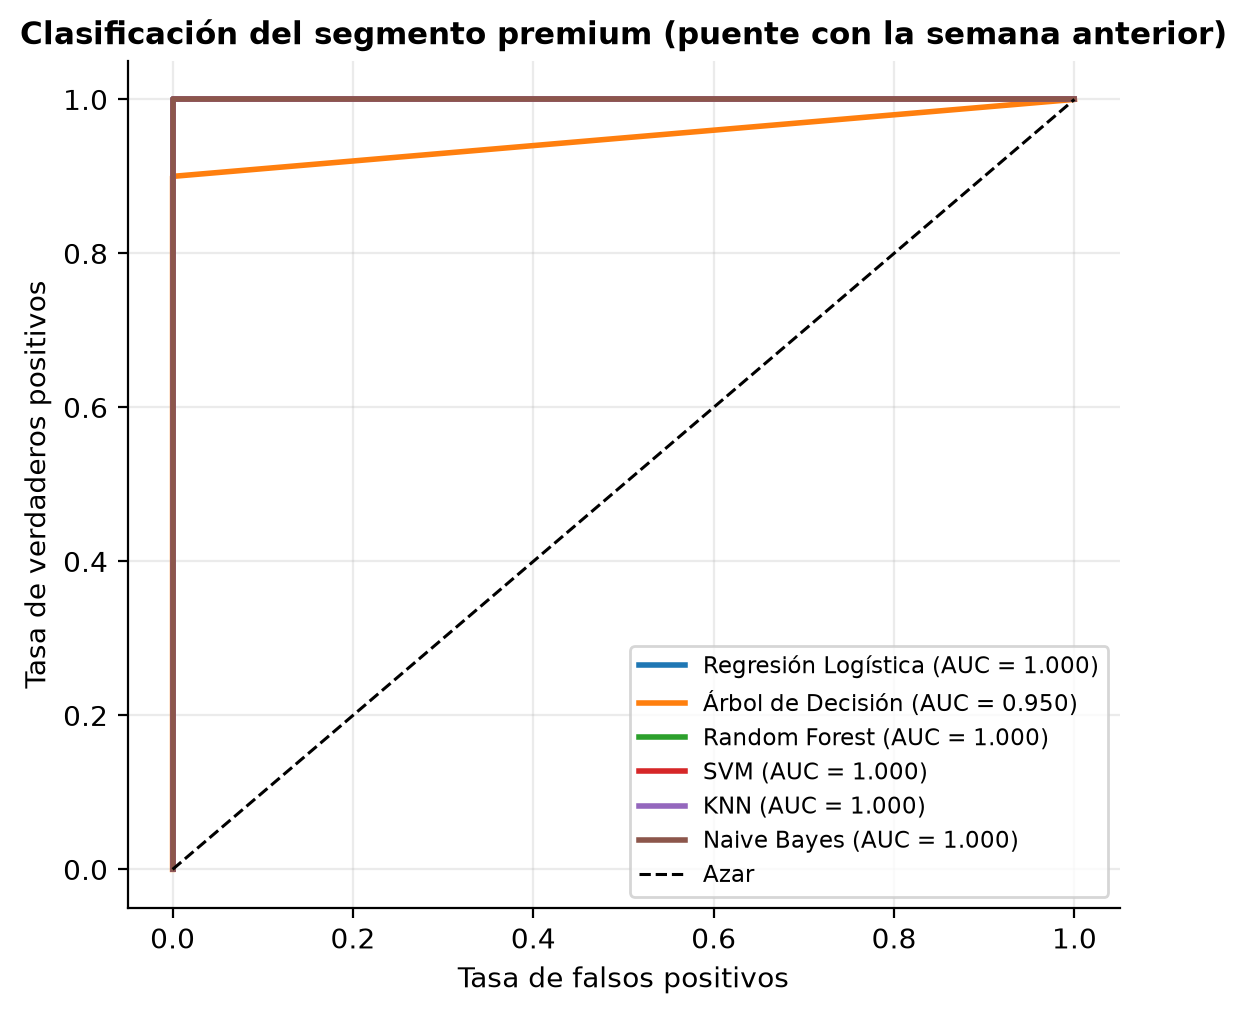

In [6]:
for f in sorted(DIR_FIGS.glob('puente_*.png')):
    display(Image(filename=str(f)))

## Lectura
* Coeficientes OLS idénticos al Excel hasta 1e-7.
* Binarizado, la regresión logística logra F1 0.947; odds ratio del área estandarizada: 24.3.
* Regresión responde «¿cuánto?» (R², RMSE); clasificación «¿cuál clase?» (recall, F1, AUC).
